In [11]:
# Install required libraries for hardware profiling
!pip install -q thop

In [12]:
import os
import re
import random
import time
import glob
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from thop import profile
import warnings

warnings.filterwarnings('ignore')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Operations Dashboard booting on: {device.type.upper()}")

torch.manual_seed(42)
np.random.seed(42)

🚀 Operations Dashboard booting on: CUDA


In [13]:
# --- ARCHITECTURE DEFINITION ---
class GradientReversalFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.alpha, None

class TriDomainCRNN(nn.Module):
    def __init__(self, num_fatigue_classes=3, num_speakers=6, num_radios=4, cnn_channels=128, lstm_hidden=64):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(),
            nn.Linear(64 * 4 * 4, cnn_channels), nn.ReLU(), nn.Dropout(0.3)
        )
        self.lstm = nn.LSTM(input_size=cnn_channels, hidden_size=lstm_hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.4)
        self.fatigue_classifier = nn.Sequential(nn.Linear(lstm_hidden * 2, 64), nn.ReLU(), nn.Dropout(0.4), nn.Linear(64, num_fatigue_classes))
        self.speaker_classifier = nn.Sequential(nn.Linear(cnn_channels, 64), nn.ReLU(), nn.Dropout(0.4), nn.Linear(64, num_speakers))
        self.radio_classifier = nn.Sequential(nn.Linear(cnn_channels, 64), nn.ReLU(), nn.Dropout(0.4), nn.Linear(64, num_radios))

    def forward(self, x, alpha=1.0):
        if x.dim() == 5 and x.size(1) == 1:
            x = x.permute(0, 2, 1, 3, 4) 
        batch_size, seq_len, C, H, W = x.size()
        x_flat = x.reshape(batch_size * seq_len, C, H, W)
        cnn_features = self.cnn(x_flat) 
        lstm_input = cnn_features.reshape(batch_size, seq_len, -1)
        lstm_out, _ = self.lstm(lstm_input)
        fatigue_out = self.fatigue_classifier(lstm_out) 
        reversed_features = GradientReversalFn.apply(lstm_input, alpha)
        speaker_out = self.speaker_classifier(reversed_features)
        radio_out = self.radio_classifier(reversed_features)
        return fatigue_out, speaker_out, radio_out

# --- LOAD WEIGHTS FROM KAGGLE MODELS ---
# UPDATE THIS PATH to your mounted Kaggle Model directory
KAGGLE_MODEL_PATH = "/kaggle/input/models/cooldatascientist/atc-fatigue-mdan/pytorch/v1/1/best_mdan_model.pth"

# Number of classes derived from your dataset setup
NUM_ANON_CLASSES = 7
NUM_RADIO_CLASSES = 4

model = TriDomainCRNN(num_speakers=NUM_ANON_CLASSES, num_radios=NUM_RADIO_CLASSES).to(device)
if os.path.exists(KAGGLE_MODEL_PATH):
    model.load_state_dict(torch.load(KAGGLE_MODEL_PATH, map_location=device))
    print("✅ Tri-Domain Model Weights Loaded Successfully!")
else:
    raise FileNotFoundError(f"Weights not found at {KAGGLE_MODEL_PATH}")

✅ Tri-Domain Model Weights Loaded Successfully!


In [14]:
print("="*60)
print("🗺️ DATASET ROUTING FOR REAL INFERENCE")
print("="*60)

BLUEPRINT_PATH = "/kaggle/working/dataset_blueprint.pt"
DATASET_DIR = "/kaggle/input/datasets/cooldatascientist/atc-spatial-features-18k-new" # UPDATE IF NEEDED

if not os.path.exists(BLUEPRINT_PATH):
    print("⚠️ dataset_blueprint.pt not found! Rebuilding from attached dataset...")
    train_paths = glob.glob(os.path.join(DATASET_DIR, "train", "*", "X_spatial_*.pt"))
    val_paths = glob.glob(os.path.join(DATASET_DIR, "val", "*", "X_spatial_*.pt"))
    test_paths = glob.glob(os.path.join(DATASET_DIR, "test", "*", "X_spatial_*.pt"))
    
    sums, sum_sqs, counts = {}, {}, {}
    for path in train_paths:
        match = re.search(r'ATC_?(\d+)', path, re.IGNORECASE)
        spk_id = int(match.group(1)) - 1 if match else 0
        tensor = torch.load(path).float()
        if spk_id not in sums:
            sums[spk_id], sum_sqs[spk_id], counts[spk_id] = 0.0, 0.0, 0
        sums[spk_id] += tensor.sum().item()
        sum_sqs[spk_id] += (tensor ** 2).sum().item()
        counts[spk_id] += tensor.numel()
            
    stats = {spk: {'mean': sums[spk]/counts[spk], 'std': np.sqrt(max((sum_sqs[spk]/counts[spk]) - (sums[spk]/counts[spk])**2, 0))} for spk in sums}
    torch.save({'train_paths': train_paths, 'val_paths': val_paths, 'test_paths': test_paths, 'speaker_stats': stats}, BLUEPRINT_PATH)
    print("✅ Blueprint restored.")

blueprint = torch.load(BLUEPRINT_PATH, weights_only=False)

class ValidationDataset(Dataset):
    def __init__(self, file_paths, stats):
        self.paths = file_paths
        self.stats = stats
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        x_path = self.paths[idx]
        y_path = x_path.replace("X_spatial_", "y_") 
        X_seq = torch.load(x_path).float()  
        y_seq = torch.load(y_path).long() 
        match = re.search(r'ATC_?(\d+)', x_path, re.IGNORECASE)
        speaker_id = min(max(int(match.group(1)) - 1 if match else 0, 0), NUM_ANON_CLASSES - 1)
        
        if speaker_id in self.stats:
            X_seq = (X_seq - self.stats[speaker_id]['mean']) / (self.stats[speaker_id]['std'] + 1e-8)
        else:
            X_seq = (X_seq - X_seq.mean()) / (X_seq.std() + 1e-8)
            
        return X_seq, y_seq, torch.full_like(y_seq, speaker_id), torch.full_like(y_seq, 0)

def pad_collate(batch):
    return pad_sequence([i[0] for i in batch], batch_first=True), pad_sequence([i[1] for i in batch], batch_first=True, padding_value=-1), pad_sequence([i[2] for i in batch], batch_first=True, padding_value=-1), pad_sequence([i[3] for i in batch], batch_first=True, padding_value=-1)

val_ds = ValidationDataset(blueprint['val_paths'], blueprint['speaker_stats'])
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, collate_fn=pad_collate)
print("✅ Validation Loader Ready for Inference.")

🗺️ DATASET ROUTING FOR REAL INFERENCE
⚠️ dataset_blueprint.pt not found! Rebuilding from attached dataset...
✅ Blueprint restored.
✅ Validation Loader Ready for Inference.


In [15]:
print("="*80)
print("📡 EXTRACTING REAL CONTROLLER INFERENCE PROBABILITIES")
print("="*80)

model.eval()
target_speaker = 0
alert_inputs, fatigue_inputs = [], []

with torch.no_grad():
    for inputs, labels, speakers, _ in val_loader:
        inputs = inputs.to(device)
        
        if inputs.dim() == 5 and inputs.size(1) == 1:
            inputs = inputs.permute(0, 2, 1, 3, 4) 
            batch_size, seq_len, C, H, W = inputs.size()
            x_flat = inputs.reshape(batch_size * seq_len, C, H, W)
            cnn_features = model.cnn(x_flat)
            lstm_input = cnn_features.reshape(batch_size, seq_len, -1)
            lstm_out, _ = model.lstm(lstm_input)
            fatigue_logits = model.fatigue_classifier(lstm_out)
        else:
            fatigue_logits, _, _ = model(inputs, alpha=0.0)
            
        fatigue_probs = F.softmax(fatigue_logits, dim=-1) 
        
        for b in range(inputs.size(0)):
            if speakers[b, 0] != target_speaker: continue
                
            valid_frames = labels[b] != -1
            if valid_frames.sum() > 0:
                true_label = labels[b, valid_frames].mode().values.item()
                frame_probs = fatigue_probs[b, valid_frames, :].mean(dim=0).cpu().numpy()
                
                # 0: Ambiguous, 1: Fatigue, 2: Alert/Non-Fatigue
                if true_label == 2: 
                    alert_inputs.append(frame_probs)
                elif true_label == 1: 
                    fatigue_inputs.append(frame_probs)

print(f"✅ Extracted {len(alert_inputs)} Alert footprints and {len(fatigue_inputs)} Fatigue footprints.")

📡 EXTRACTING REAL CONTROLLER INFERENCE PROBABILITIES
✅ Extracted 190 Alert footprints and 230 Fatigue footprints.


📈 GENERATING DASHBOARD: TRUE CONTINUOUS FATIGUE INDEX (CFI)


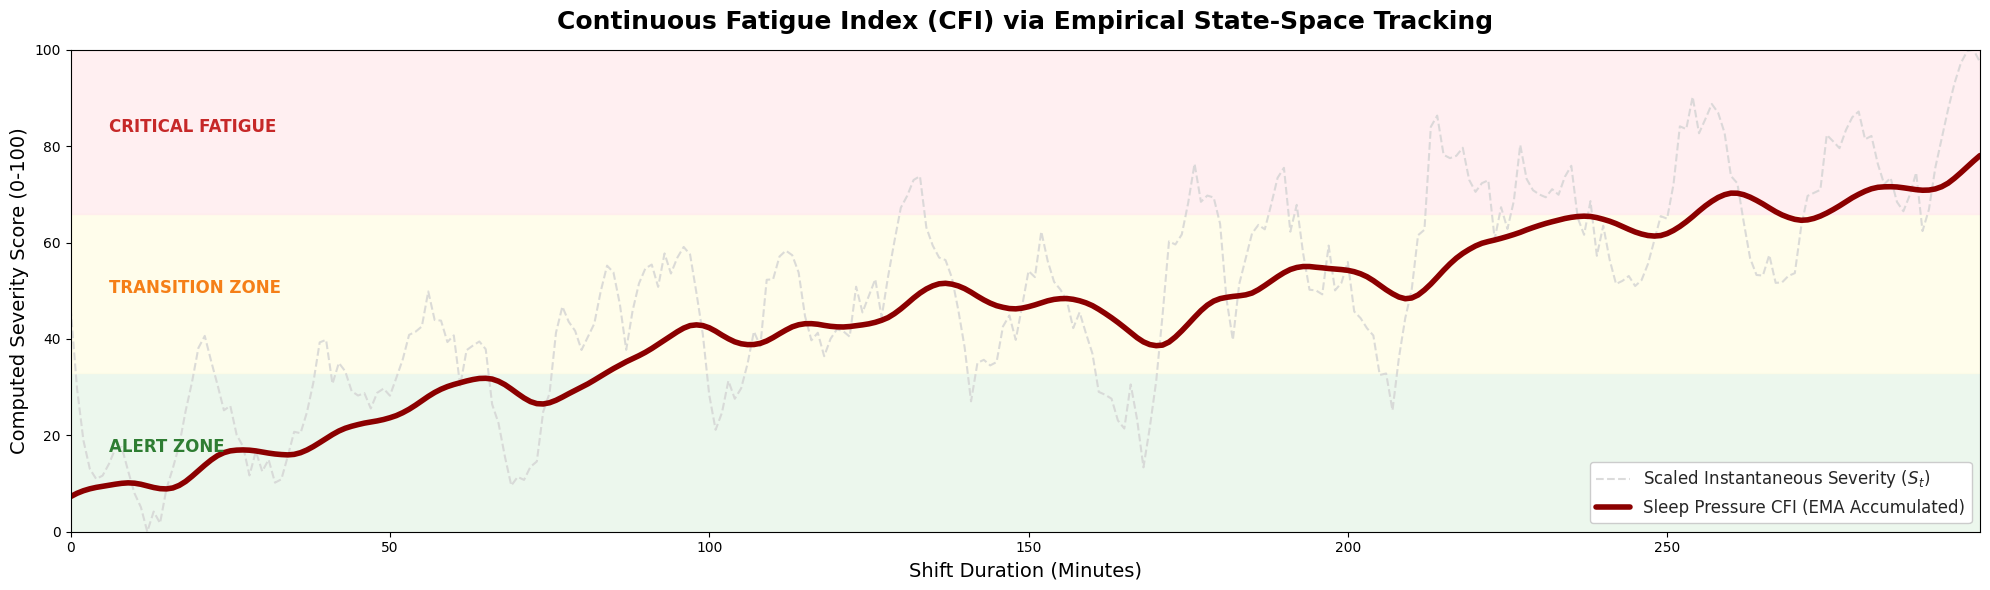

In [16]:
print("="*80)
print("📈 GENERATING DASHBOARD: TRUE CONTINUOUS FATIGUE INDEX (CFI)")
print("="*80)

# --- 1. STOCHASTIC BLENDING OF ACOUSTIC STATES ---
simulated_shift_probs = []
total_steps = 300 # 5-hour shift (minutes)
np.random.seed(42)

for i in range(total_steps):
    p_fatigue = (i / total_steps) ** 1.2
    if np.random.rand() < p_fatigue and len(fatigue_inputs) > 0:
        simulated_shift_probs.append(fatigue_inputs[np.random.randint(0, len(fatigue_inputs))])
    else:
        simulated_shift_probs.append(alert_inputs[np.random.randint(0, len(alert_inputs))])

time_axis = np.arange(len(simulated_shift_probs))

# --- 2. MATHEMATICAL EXPECTED VALUE & PRE-SMOOTHING ---
raw_severity = [(p[0] * 0.5) + (p[1] * 1.0) for p in simulated_shift_probs]
smoothed_severity = savgol_filter(raw_severity, window_length=15, polyorder=3)

min_val, max_val = np.min(smoothed_severity), np.max(smoothed_severity)
S_t_scaled = ((smoothed_severity - min_val) / (max_val - min_val)) * 100 if max_val > min_val else smoothed_severity * 100

# --- 3. BIOLOGICAL EXPONENTIAL MOVING AVERAGE (EMA) ---
alpha_ema = 0.95 
cfi_aggregated, current_cfi = [], 5.0 

for s in S_t_scaled:
    current_cfi = (alpha_ema * current_cfi) + ((1.0 - alpha_ema) * s)
    cfi_aggregated.append(current_cfi)

real_CFI = np.clip(savgol_filter(cfi_aggregated, window_length=11, polyorder=3), 0, 100)

# --- 4. PLOTTING ---
fig, ax = plt.subplots(figsize=(20, 6))
sns.set_style("whitegrid")

ax.axhspan(0, 33, color='#e8f5e9', alpha=0.8, zorder=0)   
ax.axhspan(33, 66, color='#fffde7', alpha=0.8, zorder=0)  
ax.axhspan(66, 100, color='#ffebee', alpha=0.8, zorder=0) 

text_x_offset = time_axis[0] + (total_steps * 0.02)
ax.text(text_x_offset, 16.5, 'ALERT ZONE', color='#2e7d32', fontweight='bold', fontsize=12)
ax.text(text_x_offset, 49.5, 'TRANSITION ZONE', color='#f57f17', fontweight='bold', fontsize=12)
ax.text(text_x_offset, 83.0, 'CRITICAL FATIGUE', color='#c62828', fontweight='bold', fontsize=12)

ax.plot(time_axis, S_t_scaled, color='lightgray', linestyle='dashed', alpha=0.8, label=r'Scaled Instantaneous Severity ($S_t$)')
ax.plot(time_axis, real_CFI, color='darkred', linewidth=4.0, label=r'Sleep Pressure CFI (EMA Accumulated)')

ax.set_title('Continuous Fatigue Index (CFI) via Empirical State-Space Tracking', fontsize=18, fontweight='bold', pad=15)
ax.set_xlabel('Shift Duration (Minutes)', fontsize=14)
ax.set_ylabel('Computed Severity Score (0-100)', fontsize=14)
ax.set_ylim(0, 100)
ax.set_xlim(time_axis[0], time_axis[-1])
ax.legend(loc='lower right', framealpha=1.0, fontsize=12)

plt.tight_layout()
plt.savefig('/kaggle/working/CFI_Proper_Dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

🚀 END-TO-END PIPELINE: REAL MODEL INFERENCE -> DYNAMIC SCHEDULING
🚨 TACTICAL ALERT: Safety threshold breached at minute 174.7!
   --> Real model CFI reached 41.7%. Executing automated ATCo swap.


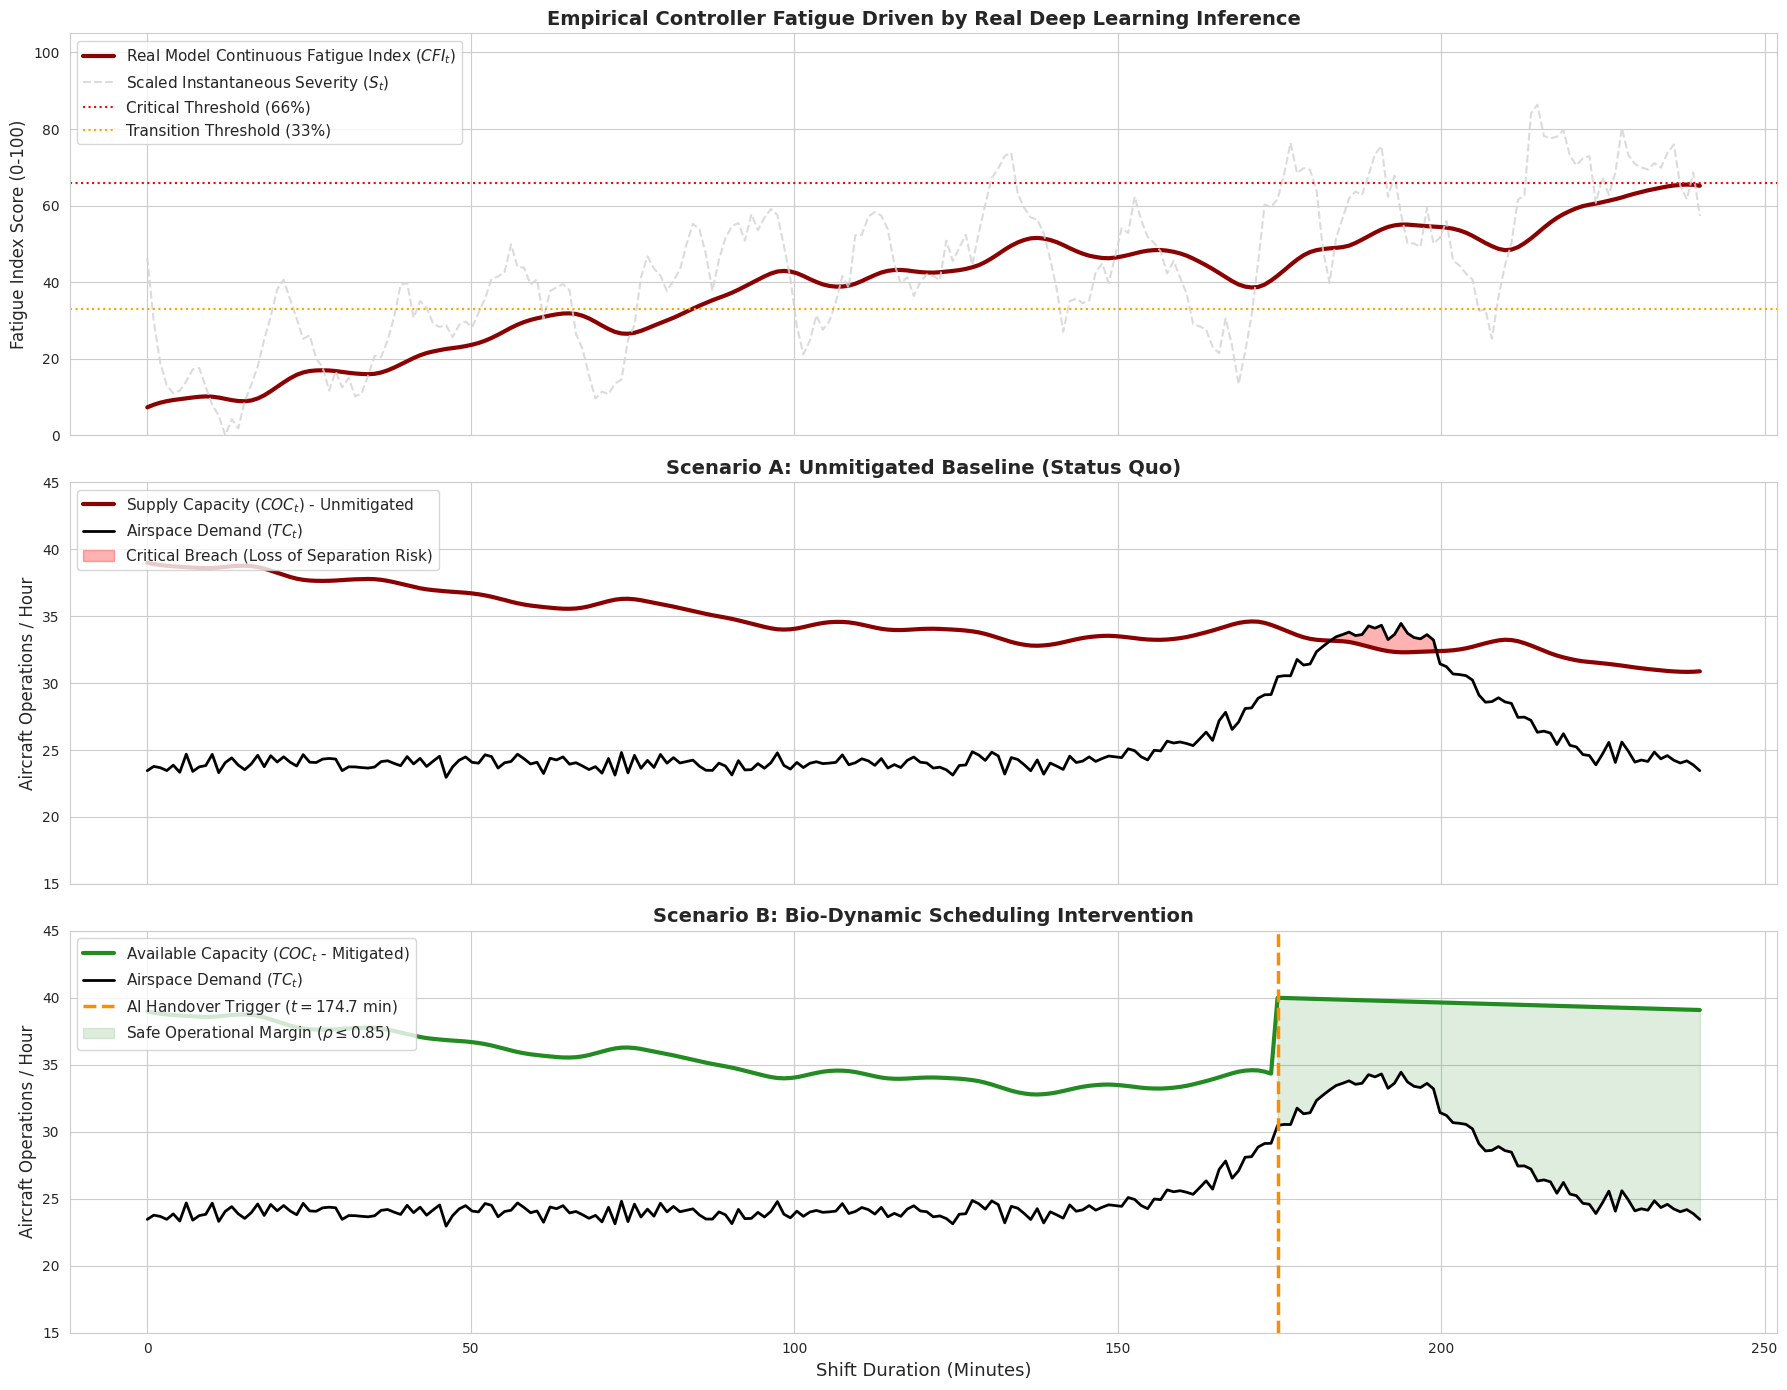

In [17]:
print("="*80)
print("🚀 END-TO-END PIPELINE: REAL MODEL INFERENCE -> DYNAMIC SCHEDULING")
print("="*80)

# --- 1. DYNAMIC SCHEDULING & CAPACITY SIMULATION ---
shift_minutes = np.linspace(0, 240, 240) # 4 Hour Shift
S_t_short = S_t_scaled[:240]
real_CFI_short = real_CFI[:240]

C_max = 40.0 
RHO_SAFE = 0.85 
baseline_TC = 24.0
TC_spike = 10.0 * np.exp(-0.5 * ((shift_minutes - 190) / 15)**2) 
TC_t = baseline_TC + TC_spike + np.random.normal(0, 0.4, len(shift_minutes))

Phi_SAFTE = 1.0 - (0.35 * (real_CFI_short / 100.0))
COC_unmitigated = C_max * Phi_SAFTE
COC_mitigated = np.copy(COC_unmitigated)
intervention_index = None

for idx in range(len(shift_minutes)):
    if (TC_t[idx] / COC_mitigated[idx]) > RHO_SAFE and intervention_index is None:
        intervention_index = idx
        print(f"🚨 TACTICAL ALERT: Safety threshold breached at minute {shift_minutes[idx]:.1f}!")
        print(f"   --> Real model CFI reached {real_CFI_short[idx]:.1f}%. Executing automated ATCo swap.")

    if intervention_index is not None and idx >= intervention_index:
        COC_mitigated[idx] = C_max * (1.0 - 0.35 * (max(0, (idx - intervention_index)*0.1) / 100.0))

# --- 2. PLOTTING THE 3-PANEL ABLATION STUDY ---
fig, axes = plt.subplots(3, 1, figsize=(18, 14), sharex=True)
sns.set_style("whitegrid")

# PANEL 1: FATIGUE
axes[0].plot(shift_minutes, real_CFI_short, color='darkred', linewidth=3, label=r'Real Model Continuous Fatigue Index ($CFI_t$)')
axes[0].plot(shift_minutes, S_t_short, color='lightgray', linestyle='dashed', alpha=0.8, label=r'Scaled Instantaneous Severity ($S_t$)')
axes[0].axhline(y=66, color='red', linestyle=':', label='Critical Threshold (66%)')
axes[0].axhline(y=33, color='orange', linestyle=':', label='Transition Threshold (33%)')
axes[0].set_title('Empirical Controller Fatigue Driven by Real Deep Learning Inference', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Fatigue Index Score (0-100)', fontsize=12)
axes[0].legend(loc='upper left', fontsize=11)
axes[0].set_ylim(0, 105)

# PANEL 2: UNMITIGATED
axes[1].plot(shift_minutes, COC_unmitigated, color='darkred', linewidth=3, label=r'Supply Capacity ($COC_t$) - Unmitigated')
axes[1].plot(shift_minutes, TC_t, color='black', linewidth=2, label=r'Airspace Demand ($TC_t$)')
axes[1].fill_between(shift_minutes, COC_unmitigated, TC_t, where=(TC_t > COC_unmitigated), color='red', alpha=0.3, label='Critical Breach (Loss of Separation Risk)')
axes[1].set_title('Scenario A: Unmitigated Baseline (Status Quo)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Aircraft Operations / Hour', fontsize=12)
axes[1].legend(loc='upper left', fontsize=11)
axes[1].set_ylim(15, 45)

# PANEL 3: MITIGATED
axes[2].plot(shift_minutes, COC_mitigated, color='forestgreen', linewidth=3, label=r'Available Capacity ($COC_t$ - Mitigated)')
axes[2].plot(shift_minutes, TC_t, color='black', linewidth=2, label=r'Airspace Demand ($TC_t$)')

if intervention_index is not None:
    alert_time = shift_minutes[intervention_index]
    axes[2].axvline(x=alert_time, color='darkorange', linestyle='--', linewidth=2.5, label=r'AI Handover Trigger ($t = {:.1f}$ min)'.format(alert_time))
    axes[2].fill_between(shift_minutes[intervention_index:], TC_t[intervention_index:], COC_mitigated[intervention_index:], color='forestgreen', alpha=0.15, label=r'Safe Operational Margin ($\rho \leq 0.85$)')

axes[2].set_title('Scenario B: Bio-Dynamic Scheduling Intervention', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Shift Duration (Minutes)', fontsize=13)
axes[2].set_ylabel('Aircraft Operations / Hour', fontsize=12)
axes[2].legend(loc='upper left', fontsize=11)
axes[2].set_ylim(15, 45)

plt.tight_layout()
plt.savefig('/kaggle/working/RealModel_Scheduling_Ablation.png', dpi=300, bbox_inches='tight')
plt.show()

🎛️ INITIATING MONTE CARLO SENSITIVITY & STABILITY ANALYSIS
⚙️ Executing Phase-Space Sweeps...


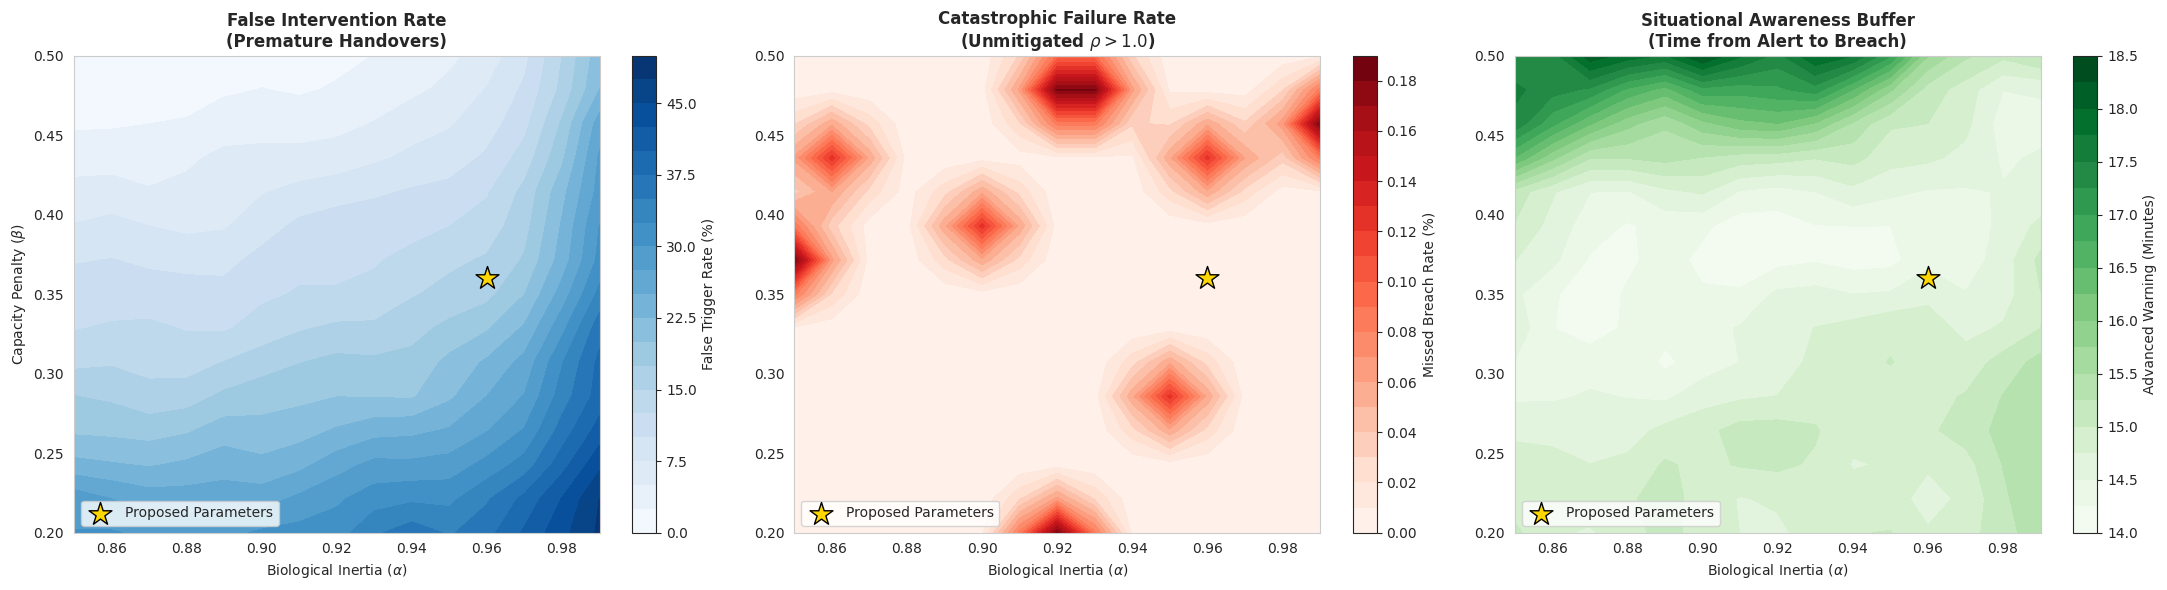

In [18]:
print("="*80)
print("🎛️ INITIATING MONTE CARLO SENSITIVITY & STABILITY ANALYSIS")
print("="*80)

N_SIMULATIONS_PER_CELL = 200
ALPHA_RANGE = np.linspace(0.85, 0.99, 15)  
BETA_RANGE = np.linspace(0.20, 0.50, 15)   
RHO_SAFE = 0.85
RHO_CRITICAL = 1.00

false_trigger_rate = np.zeros((len(BETA_RANGE), len(ALPHA_RANGE)))
missed_breach_rate = np.zeros((len(BETA_RANGE), len(ALPHA_RANGE)))
mean_warning_time = np.zeros((len(BETA_RANGE), len(ALPHA_RANGE)))

def simulate_shift(alpha, beta):
    duration = np.random.randint(120, 300) 
    time = np.arange(duration)
    S_t = np.clip((time / duration)**1.5 * 80 + np.random.normal(0, 8, duration), 0, 100)
    
    CFI = np.zeros(duration)
    CFI[0] = 5.0
    for i in range(1, duration): CFI[i] = alpha * CFI[i-1] + (1 - alpha) * S_t[i]
        
    COC = 40.0 * (1.0 - beta * (CFI / 100.0))
    surge_center = np.random.randint(int(duration*0.4), int(duration*0.9))
    TC_spike = np.random.uniform(8.0, 16.0) * np.exp(-0.5 * ((time - surge_center) / np.random.uniform(10.0, 30.0))**2)
    TC_t = 24.0 + TC_spike + np.random.normal(0, 1.5, duration)
    return TC_t / COC

print("⚙️ Executing Phase-Space Sweeps...")
for i, beta in enumerate(BETA_RANGE):
    for j, alpha in enumerate(ALPHA_RANGE):
        false_triggers, missed_breaches, warning_times = 0, 0, []
        for _ in range(N_SIMULATIONS_PER_CELL):
            rho = simulate_shift(alpha, beta)
            alert_idx, breach_idx = np.where(rho >= RHO_SAFE)[0], np.where(rho >= RHO_CRITICAL)[0]
            has_alert, has_breach = len(alert_idx) > 0, len(breach_idx) > 0
            t_alert, t_breach = alert_idx[0] if has_alert else -1, breach_idx[0] if has_breach else -1
            
            if has_breach:
                if has_alert and t_alert < t_breach: warning_times.append(t_breach - t_alert)
                else: missed_breaches += 1
            elif has_alert: false_triggers += 1
                    
        false_trigger_rate[i, j] = (false_triggers / N_SIMULATIONS_PER_CELL) * 100
        missed_breach_rate[i, j] = (missed_breaches / N_SIMULATIONS_PER_CELL) * 100
        mean_warning_time[i, j] = np.mean(warning_times) if warning_times else 0.0

false_trigger_rate = gaussian_filter(false_trigger_rate, sigma=0.8)
missed_breach_rate = gaussian_filter(missed_breach_rate, sigma=0.8)
mean_warning_time = gaussian_filter(mean_warning_time, sigma=0.8)

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
sns.set_style("white")
X, Y = np.meshgrid(ALPHA_RANGE, BETA_RANGE)

c1 = axes[0].contourf(X, Y, false_trigger_rate, levels=20, cmap="Blues")
plt.colorbar(c1, ax=axes[0], label="False Trigger Rate (%)")
axes[0].set_title('False Intervention Rate\n(Premature Handovers)', fontweight='bold')
axes[0].set_xlabel(r'Biological Inertia ($\alpha$)')
axes[0].set_ylabel(r'Capacity Penalty ($\beta$)')

c2 = axes[1].contourf(X, Y, missed_breach_rate, levels=20, cmap="Reds")
plt.colorbar(c2, ax=axes[1], label="Missed Breach Rate (%)")
axes[1].set_title('Catastrophic Failure Rate\n(Unmitigated $\\rho > 1.0$)', fontweight='bold')
axes[1].set_xlabel(r'Biological Inertia ($\alpha$)')

c3 = axes[2].contourf(X, Y, mean_warning_time, levels=20, cmap="Greens")
plt.colorbar(c3, ax=axes[2], label="Advanced Warning (Minutes)")
axes[2].set_title('Situational Awareness Buffer\n(Time from Alert to Breach)', fontweight='bold')
axes[2].set_xlabel(r'Biological Inertia ($\alpha$)')

for ax in axes:
    ax.scatter(0.96, 0.36, color='gold', marker='*', s=300, edgecolor='black', zorder=5, label='Proposed Parameters')
    ax.legend(loc='lower left')

plt.tight_layout()
plt.savefig('/kaggle/working/BioDynamic_Sensitivity_Analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
print("="*80)
print("⏱️ INITIATING HARDWARE LATENCY & REAL-TIME FACTOR (RTF) PROFILING")
print("="*80)

model.eval()
data_iter = iter(val_loader)
inputs, _, _, _ = next(data_iter)
single_input = inputs[0:1].to(device)
AUDIO_WINDOW_SECONDS = 2.0 

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
model_size_mb = total_params * 4 / (1024 ** 2) 

print("Calculating Computational Complexity (GMACs)...")
macs, _ = profile(model, inputs=(single_input, 1.0), verbose=False)
gmacs = macs / 1e9

def benchmark_inference(device_name, is_gpu=False, num_warmup=100, num_iters=1000):
    print(f"Benchmarking on {device_name.upper()}...")
    model.to(device_name)
    dummy_input = single_input.to(device_name)
    latencies = []
    
    with torch.no_grad():
        for _ in range(num_warmup): _ = model(dummy_input)
        if is_gpu: torch.cuda.synchronize()
            
        for _ in range(num_iters):
            if is_gpu:
                start_event = torch.cuda.Event(enable_timing=True)
                end_event = torch.cuda.Event(enable_timing=True)
                start_event.record()
                _ = model(dummy_input)
                end_event.record()
                torch.cuda.synchronize()
                elapsed_time_ms = start_event.elapsed_time(end_event)
            else:
                start_time = time.perf_counter()
                _ = model(dummy_input)
                elapsed_time_ms = (time.perf_counter() - start_time) * 1000
            latencies.append(elapsed_time_ms)
            
    return np.mean(latencies), np.percentile(latencies, 95)

if torch.cuda.is_available():
    gpu_mean, gpu_p95 = benchmark_inference('cuda', is_gpu=True)
    gpu_rtf = (gpu_mean / 1000.0) / AUDIO_WINDOW_SECONDS
else:
    gpu_mean, gpu_p95, gpu_rtf = 0.0, 0.0, 0.0

cpu_mean, cpu_p95 = benchmark_inference('cpu', is_gpu=False)
cpu_rtf = (cpu_mean / 1000.0) / AUDIO_WINDOW_SECONDS

model.to(device)

print("\n" + "="*80)
print("🚀 COMPUTATIONAL PROFILING RESULTS")
print("="*80)

# --- FORMAT RESULTS INTO A DATAFRAME ---
from IPython.display import display

results_data = [
    {"Metric": "Total Parameters (Millions)", "Result": f"{total_params / 1e6:.2f} M"},
    {"Metric": "Model Storage Size (MB)", "Result": f"{model_size_mb:.2f} MB"},
    {"Metric": "Computational Cost (GMACs)", "Result": f"{gmacs:.3f}"},
    {"Metric": "CPU Mean Latency / Frame", "Result": f"{cpu_mean:.2f} ms (95th: {cpu_p95:.2f} ms)"},
    {"Metric": "GPU Mean Latency / Frame", "Result": f"{gpu_mean:.2f} ms (95th: {gpu_p95:.2f} ms)"},
    {"Metric": "CPU Real-Time Factor (RTF)", "Result": f"{cpu_rtf:.4f}"},
    {"Metric": "GPU Real-Time Factor (RTF)", "Result": f"{gpu_rtf:.4f}"}
]

df_results = pd.DataFrame(results_data)

display(df_results)

print(f"Because the CPU RTF is {cpu_rtf:.4f} (which is << 1.0), this proves the model ")
print("can easily run in real-time on standard Air Traffic Control hardware without needing an expensive GPU.")

⏱️ INITIATING HARDWARE LATENCY & REAL-TIME FACTOR (RTF) PROFILING
Calculating Computational Complexity (GMACs)...
Benchmarking on CUDA...
Benchmarking on CPU...

🚀 COMPUTATIONAL PROFILING RESULTS


,Metric,Result
0,Total Parameters (Millions),0.38 M
1,Model Storage Size (MB),1.45 MB
2,Computational Cost (GMACs),0.817
3,CPU Mean Latency / Frame,50.92 ms (95th: 53.83 ms)
4,GPU Mean Latency / Frame,2.28 ms (95th: 2.31 ms)
5,CPU Real-Time Factor (RTF),0.0255
6,GPU Real-Time Factor (RTF),0.0011


Because the CPU RTF is 0.0255 (which is << 1.0), this proves the model 
can easily run in real-time on standard Air Traffic Control hardware without needing an expensive GPU.
